In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 02 · EDA — Venta cruzada de seguro de vehículo

El EDA **no es hacer gráficos**: es descubrir qué decisiones hay que tomar antes de modelar. Este notebook termina con una
**tabla de decisiones**, cada una con una cifra y un motivo, que se copia a `reports/01_eda.md`.

**Preguntas guía:** (1) unidad de análisis · (2) objetivo · (3) suciedad · (4) qué debería ser estable · (5) sospecha de fuga ·
**(6) qué variables se relacionan con la respuesta `Response`** y cuánto.

Especificación de esta etapa: `especificaciones/02-eda.md`. Caso y métricas: `reports/00_caso.md`.

## 0. Cargar los datos

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd().resolve().parent
RAW_DIR = ROOT / "data" / "raw"
files = sorted(p for p in RAW_DIR.glob("*") if p.suffix.lower() in {".csv", ".parquet", ".xlsx"})
# El dataset del grupo hoy está en la raíz del repo; si se mueve a data/raw/, se usa ese.
path = files[0] if files else ROOT / "dataset.csv"
df = pd.read_csv(path)
print(f"{path.name}: {df.shape[0]:,} filas x {df.shape[1]} columnas")
# Datos personales: no hay nombres, documentos ni teléfonos. `id` es un consecutivo sin información.

ID_COL = "id"          # identifica al cliente
TARGET = "Response"    # 1 = interesado en el seguro de vehículo, 0 = no

# Porción de exploración: la MISMA partición de la etapa 03 (80 %, estratificada, semilla 42).
# Todo cálculo que use Response se hace sobre `explore`; `holdout` (20 % de prueba) no se mira.
from proyecto.data.split import split_train_test
explore, holdout = split_train_test(df)
df.head()

dataset.csv: 381,109 filas x 12 columnas


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


## 1. ¿Cuál es la unidad de análisis? ¿Qué representa una fila?

In [3]:
print("filas:", len(df), "| columnas:", df.shape[1])
print("clientes distintos:", df[ID_COL].nunique())
print("filas por cliente:", df.groupby(ID_COL).size().value_counts().to_dict())

filas: 381109 | columnas: 12
clientes distintos: 381109
filas por cliente: {1: 381109}


**Mi respuesta (una frase):** una fila es **un cliente actual del seguro de salud** con su vehículo y su respuesta a la oferta del seguro
de vehículo; los 381.109 `id` son distintos, así que **ningún cliente se repite**.

**Unidad por la que partiré los datos:** por fila (= por cliente), **estratificado por `Response`** para conservar el 12,26 % de positivos
en cada parte. No se necesita partición por grupo.

## 2. ¿Cómo está el objetivo?

In [4]:
print(df[TARGET].value_counts().rename("filas").to_frame().assign(proporcion=df[TARGET].value_counts(normalize=True).round(4)))
print("vacíos en el objetivo:", df[TARGET].isna().sum())
print(f"Exactitud de predecir siempre 'no interesado': {1 - df[TARGET].mean():.4f}")

           filas  proporcion
Response                    
0         334399      0.8774
1          46710      0.1226
vacíos en el objetivo: 0
Exactitud de predecir siempre 'no interesado': 0.8774


**Hallazgo:** `Response` no tiene vacíos y está desbalanceado: **46.710 interesados (12,26 %)** frente a 334.399 no interesados (87,74 %).

**Línea base (qué resultado obtiene una regla trivial):** decir siempre "no interesado" acierta el **87,74 %** y no encuentra a nadie;
por eso la exactitud no sirve. En costo esperado (matriz 5 a 1, `reports/00_caso.md`) la mejor regla simple da 0,373 por cliente.

## 3. ¿Qué tan sucios están los datos y de qué manera?

Chequeos de la sección 3 de la guía: tipos, vacíos, duplicados, valores imposibles o centinela, códigos guardados como número
y categorías raras.

In [5]:
print(df.dtypes, "\n")
print("vacíos por columna:", int(df.isna().sum().sum()))
features = [c for c in df.columns if c != ID_COL]
dup_mask = df.duplicated(subset=features, keep=False)
print("filas duplicadas exactas:", df.duplicated().sum())
print("filas duplicadas sin contar el id:", df.duplicated(subset=features).sum())
same_x = [c for c in features if c != TARGET]
conflict = df[df.duplicated(subset=same_x, keep=False)].groupby(same_x)[TARGET].nunique().gt(1).sum()
print("grupos con las mismas variables pero distinta respuesta:", conflict)

id                        int64
Gender                      str
Age                       int64
Driving_License           int64
Region_Code             float64
Previously_Insured        int64
Vehicle_Age                 str
Vehicle_Damage              str
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                   int64
Response                  int64
dtype: object 

vacíos por columna: 0


filas duplicadas exactas: 0
filas duplicadas sin contar el id: 269


grupos con las mismas variables pero distinta respuesta: 53


In [6]:
num = ["Age", "Annual_Premium", "Vintage"]
df[num].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.round(1)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Age,381109.0,38.8,15.5,20.0,20.0,21.0,25.0,36.0,49.0,69.0,77.0,85.0
Annual_Premium,381109.0,30564.4,17213.2,2630.0,2630.0,2630.0,24405.0,31669.0,39400.0,55176.0,72963.0,540165.0
Vintage,381109.0,154.3,83.7,10.0,12.0,24.0,82.0,154.0,227.0,285.0,297.0,299.0


In [7]:
# Annual_Premium: ¿el mínimo es un valor real o un piso / centinela?
ap_min = df["Annual_Premium"].min()
at_min = df["Annual_Premium"].eq(ap_min)
print(f"valor mínimo: {ap_min:,.0f} | filas con ese valor: {at_min.sum():,} ({at_min.mean():.2%})")
print("siguiente valor más bajo:", f"{df.loc[~at_min, 'Annual_Premium'].min():,.0f}")
ex_min = explore["Annual_Premium"].eq(ap_min)   # la tasa usa Response: solo en exploración
print(f"tasa de interés con el mínimo (exploración): {explore.loc[ex_min, TARGET].mean():.4f} | resto: {explore.loc[~ex_min, TARGET].mean():.4f}")
# Valores extremos por regla IQR
q1, q3 = df["Annual_Premium"].quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print(f"límite superior IQR: {upper:,.0f} | filas por encima: {df['Annual_Premium'].gt(upper).sum():,} ({df['Annual_Premium'].gt(upper).mean():.2%})")

valor mínimo: 2,630 | filas con ese valor: 64,877 (17.02%)
siguiente valor más bajo: 6,098
tasa de interés con el mínimo (exploración): 0.1310 | resto: 0.1208
límite superior IQR: 61,892 | filas por encima: 10,320 (2.71%)


In [8]:
# Códigos guardados como número decimal y cardinalidad
for c in ["Region_Code", "Policy_Sales_Channel"]:
    vc = df[c].value_counts()
    print(f"{c}: {df[c].dtype}, ¿todos enteros? {bool((df[c] % 1 == 0).all())}, categorías: {vc.size}, "
          f"categorías con < 1.000 filas: {(vc < 1000).sum()} (suman {vc[vc < 1000].sum() / len(df):.2%} de las filas), "
          f"las 5 más grandes cubren {vc.head(5).sum() / len(df):.2%}")
print("\nDriving_License:", df["Driving_License"].value_counts().to_dict())
print("Vehicle_Age:", df["Vehicle_Age"].value_counts().to_dict())
print("Gender:", df["Gender"].value_counts().to_dict())

Region_Code: float64, ¿todos enteros? True, categorías: 53, categorías con < 1.000 filas: 4 (suman 0.49% de las filas), las 5 más grandes cubren 50.28%
Policy_Sales_Channel: float64, ¿todos enteros? True, categorías: 155, categorías con < 1.000 filas: 134 (suman 4.12% de las filas), las 5 más grandes cubren 84.21%

Driving_License: {1: 380297, 0: 812}
Vehicle_Age: {'1-2 Year': 200316, '< 1 Year': 164786, '> 2 Years': 16007}
Gender: {'Male': 206089, 'Female': 175020}


**Hallazgos de calidad (con cifras):**
- **Sin vacíos** en ninguna columna y sin duplicados exactos.
- **269 filas repetidas** si se ignora el `id` (0,07 %); en **53** de esos grupos la misma combinación de variables tiene respuestas distintas.
- **`Annual_Premium` tiene un piso:** el valor mínimo **2.630 aparece en 64.877 filas (17,02 %)** y el siguiente valor es 6.098. Parece
  una prima mínima o un valor por defecto, no un monto real. Su tasa de interés (13,1 %) es parecida al resto (12,1 %).
- **`Annual_Premium` tiene cola larga:** mediana 31.669, p99 72.963 y máximo 540.165; **10.320 filas (2,71 %)** superan el límite IQR (61.892).
- **`Region_Code` y `Policy_Sales_Channel` son códigos guardados como decimales** (todos enteros). Region: 53 códigos, 4 con menos de 1.000 filas.
  Canal: 155 códigos, **134 con menos de 1.000 filas** (suman 4,12 %); los 5 mayores cubren el 84,2 %.
- **`Driving_License = 0` solo en 812 filas (0,21 %)**: variable casi constante.
- `Age` (20–85) y `Vintage` (10–299 días) no tienen valores imposibles.

## 4. ¿Qué variables deberían ser estables y no lo son?

Solo aplica si una entidad aparece en varias filas.

In [9]:
print("clientes con más de una fila:", int(df.groupby(ID_COL).size().gt(1).sum()))

clientes con más de una fila: 0


**Hallazgo:** no aplica: ningún cliente tiene más de una fila (0 clientes repetidos).

**¿Ruido o cambio real? ¿Por qué?** No hay forma de medirlo con una sola fila por cliente; no hay variables que comparar en el tiempo.

## 5. ¿Hay algo que suene a fuga de información?

Primer filtro de la guía: ¿alguna columna casi idéntica al objetivo? Luego la pregunta de negocio: ¿se conoce **antes** de decidir a quién llamar?

In [10]:
# Usa Response: se calcula solo en la porción de exploración
for c in [c for c in explore.columns if c not in (ID_COL, TARGET)]:
    if explore[c].nunique() < 30:
        purity = pd.crosstab(explore[c], explore[TARGET], normalize="index").max(axis=1).mean()
        print(f"{c:22s} pureza media por categoría = {purity:.2f}")

Gender                 pureza media por categoría = 0.88


Driving_License        pureza media por categoría = 0.91


Previously_Insured     pureza media por categoría = 0.89


Vehicle_Age            pureza media por categoría = 0.83
Vehicle_Damage         pureza media por categoría = 0.88


**Columnas sospechosas de fuga y por qué:**
- **Ninguna columna es casi idéntica al objetivo:** la pureza por categoría (0,83–0,91) es la misma que da la clase mayoritaria (0,88).
- **`Policy_Sales_Channel` (sospechosa):** es el canal por el que se contactó al cliente. Si el canal se asigna **en** la campaña, no se
  conoce antes de decidir a quién llamar. Se mide el modelo **con y sin** ella en la etapa 04.
- `Previously_Insured`, `Vehicle_Damage`, `Vehicle_Age`, `Vintage`, `Age`, `Gender`, `Region_Code`, `Annual_Premium` se conocen antes del contacto.

## 6. ¿Qué variables se relacionan con la respuesta?

Esta es la pregunta central del EDA para el modelado. **Para no mirar el conjunto de prueba** (regla 4 del proyecto), la relación con
`Response` se mide solo en una porción de exploración: el 80 % de los datos, partido **estratificado por `Response` con semilla 42**.
El 20 % restante queda cerrado hasta la etapa de validación, y la etapa 03 usa la misma partición.

Medidas, según el tipo de variable:

| Tipo | Medida | Cómo se lee |
|---|---|---|
| Categórica / binaria | **Tasa de interés por categoría** y **V de Cramér** (0 = nada, 1 = total) | Cuánto cambia la probabilidad de interés entre categorías |
| Numérica | **Correlación punto-biserial** (Pearson con un 0/1), **Spearman**, y **AUC univariada** (0,5 = nada) | Si a mayor valor, más (o menos) interés, y si la relación es lineal o no |
| Todas | **Información mutua** | Ranking común que también capta relaciones no lineales |

Ninguna de estas medidas decide sola qué variable entra al modelo: eso se prueba en la etapa 04 con validación.

In [11]:
# `explore` y `holdout` se definieron al cargar, con split_train_test (la misma función de la etapa 03)
base_rate = explore[TARGET].mean()
print(f"exploración: {len(explore):,} filas | prueba reservada: {len(holdout):,} filas")
print(f"tasa de interés global en exploración: {base_rate:.4f}")

exploración: 304,887 filas | prueba reservada: 76,222 filas
tasa de interés global en exploración: 0.1226


### 6.1 Variables categóricas y binarias: tasa de interés por categoría y V de Cramér

In [12]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    n = table.values.sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1)))), float(p)

cat_cols = ["Previously_Insured", "Vehicle_Damage", "Vehicle_Age", "Gender", "Driving_License", "Region_Code", "Policy_Sales_Channel"]
assoc_cat = pd.DataFrame(
    [(c, explore[c].nunique(), *cramers_v(explore[c], explore[TARGET])) for c in cat_cols],
    columns=["variable", "categorias", "v_cramer", "p_valor_chi2"],
).sort_values("v_cramer", ascending=False).set_index("variable")
assoc_cat.round(4)

,categorias,v_cramer,p_valor_chi2
variable,,,
Vehicle_Damage,2,0.3542,0.0
Previously_Insured,2,0.3413,0.0
Policy_Sales_Channel,154,0.2633,0.0
Vehicle_Age,3,0.2213,0.0
Region_Code,53,0.1374,0.0
Gender,2,0.0513,0.0
Driving_License,2,0.0100,0.0


In [13]:
def rate_table(data, col):
    g = data.groupby(col)[TARGET].agg(filas="size", interesados="sum", tasa="mean")
    g["% filas"] = (g["filas"] / len(data) * 100).round(2)
    g["lift"] = (g["tasa"] / base_rate).round(2)
    g["tasa"] = g["tasa"].round(4)
    return g

for c in ["Previously_Insured", "Vehicle_Damage", "Vehicle_Age", "Gender", "Driving_License"]:
    print(f"\n=== {c} ===")
    display(rate_table(explore, c))


=== Previously_Insured ===


,filas,interesados,tasa,% filas,lift
Previously_Insured,,,,,
0,165210,37250,0.2255,54.19,1.84
1,139677,118,0.0008,45.81,0.01



=== Vehicle_Damage ===


,filas,interesados,tasa,% filas,lift
Vehicle_Damage,,,,,
No,150928,794,0.0053,49.5,0.04
Yes,153959,36574,0.2376,50.5,1.94



=== Vehicle_Age ===


,filas,interesados,tasa,% filas,lift
Vehicle_Age,,,,,
1-2 Year,160195,27819,0.1737,52.54,1.42
< 1 Year,131852,5789,0.0439,43.25,0.36
> 2 Years,12840,3760,0.2928,4.21,2.39



=== Gender ===


,filas,interesados,tasa,% filas,lift
Gender,,,,,
Female,140107,14617,0.1043,45.95,0.85
Male,164780,22751,0.1381,54.05,1.13



=== Driving_License ===


,filas,interesados,tasa,% filas,lift
Driving_License,,,,,
0,654,34,0.0520,0.21,0.42
1,304233,37334,0.1227,99.79,1.00


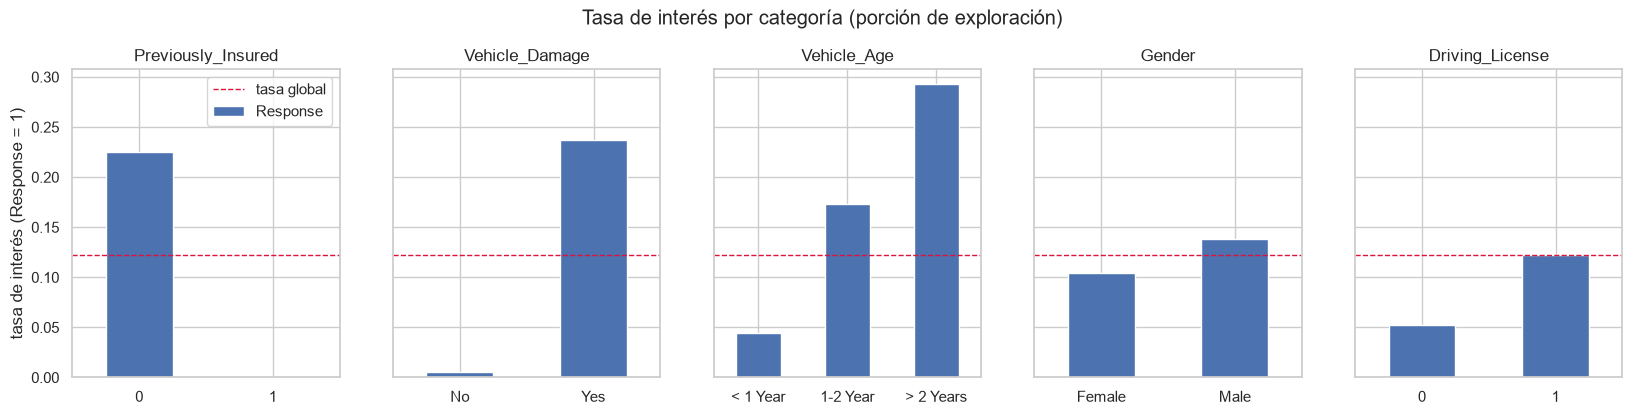

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
order_age = ["< 1 Year", "1-2 Year", "> 2 Years"]
for ax, c in zip(axes, ["Previously_Insured", "Vehicle_Damage", "Vehicle_Age", "Gender", "Driving_License"]):
    t = explore.groupby(c)[TARGET].mean()
    if c == "Vehicle_Age":
        t = t.reindex(order_age)
    t.plot.bar(ax=ax, color="#4C72B0")
    ax.axhline(base_rate, color="crimson", ls="--", lw=1, label="tasa global")
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("tasa de interés (Response = 1)")
axes[0].legend()
plt.suptitle("Tasa de interés por categoría (porción de exploración)", y=1.03)
plt.show()

### 6.2 Región y canal de venta: muchas categorías

In [15]:
for c in ["Region_Code", "Policy_Sales_Channel"]:
    t = rate_table(explore, c).sort_values("filas", ascending=False)
    big = t[t["filas"] >= 1000]
    print(f"\n=== {c} === categorías: {len(t)} | con >= 1.000 filas: {len(big)} (cubren {big['filas'].sum() / len(explore):.1%})")
    print(f"tasa entre categorías con >= 1.000 filas: mínimo {big['tasa'].min():.3f}, máximo {big['tasa'].max():.3f}")
    display(t.head(10))


=== Region_Code === categorías: 53 | con >= 1.000 filas: 48 (cubren 99.3%)
tasa entre categorías con >= 1.000 filas: mínimo 0.046, máximo 0.188


,filas,interesados,tasa,% filas,lift
Region_Code,,,,,
28.0,85152,15927,0.1870,27.93,1.53
8.0,27138,2584,0.0952,8.90,0.78
46.0,15847,1621,0.1023,5.20,0.83
41.0,14635,1818,0.1242,4.80,1.01
15.0,10577,779,0.0737,3.47,0.60
30.0,9733,719,0.0739,3.19,0.60
29.0,8866,1102,0.1243,2.91,1.01
50.0,8256,518,0.0627,2.71,0.51
11.0,7386,834,0.1129,2.42,0.92



=== Policy_Sales_Channel === categorías: 154 | con >= 1.000 filas: 17 (cubren 94.7%)
tasa entre categorías con >= 1.000 filas: mínimo 0.022, máximo 0.327


,filas,interesados,tasa,% filas,lift
Policy_Sales_Channel,,,,,
152.0,107998,3112,0.0288,35.42,0.24
26.0,63709,12722,0.1997,20.90,1.63
124.0,59187,11191,0.1891,19.41,1.54
160.0,17348,380,0.0219,5.69,0.18
156.0,8472,1797,0.2121,2.78,1.73
122.0,7951,1382,0.1738,2.61,1.42
157.0,5386,1447,0.2687,1.77,2.19
154.0,4772,1169,0.2450,1.57,2.00
151.0,3082,99,0.0321,1.01,0.26


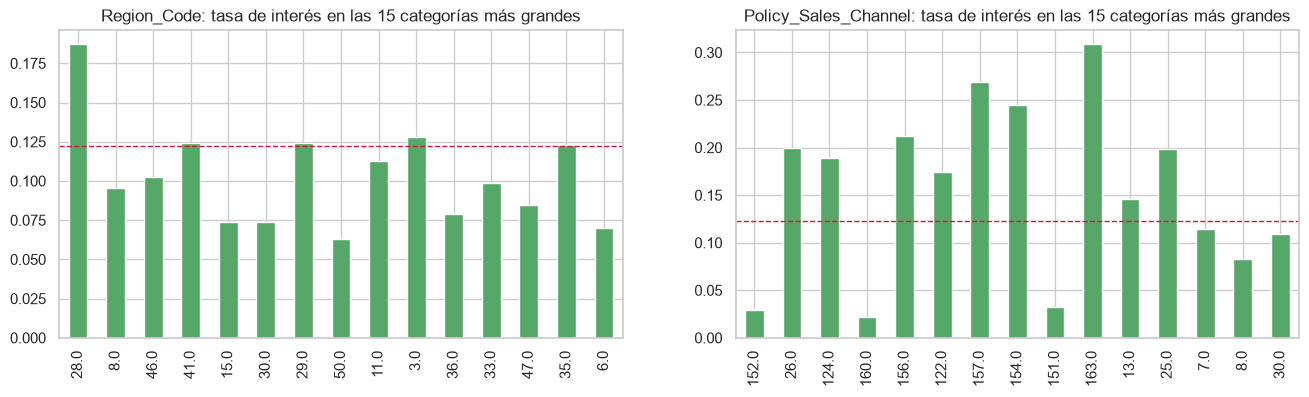

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, c in zip(axes, ["Region_Code", "Policy_Sales_Channel"]):
    t = rate_table(explore, c).sort_values("filas", ascending=False).head(15)
    t["tasa"].plot.bar(ax=ax, color="#55A868")
    ax.axhline(base_rate, color="crimson", ls="--", lw=1)
    ax.set_title(f"{c}: tasa de interés en las 15 categorías más grandes"); ax.set_xlabel("")
plt.show()

### 6.3 Variables numéricas: correlación, AUC univariada y tasa por tramos

In [17]:
from scipy.stats import pointbiserialr, spearmanr
from sklearn.metrics import roc_auc_score

rows = []
for c in num:
    r, p = pointbiserialr(explore[TARGET], explore[c])
    rho = spearmanr(explore[c], explore[TARGET]).statistic
    auc = roc_auc_score(explore[TARGET], explore[c])
    rows.append((c, r, p, rho, auc,
                 explore.loc[explore[TARGET] == 0, c].median(), explore.loc[explore[TARGET] == 1, c].median()))
assoc_num = pd.DataFrame(rows, columns=["variable", "r_punto_biserial", "p_valor", "spearman", "auc_univariada",
                                       "mediana_no", "mediana_si"]).set_index("variable")
assoc_num.round(4)

,r_punto_biserial,p_valor,spearman,auc_univariada,mediana_no,mediana_si
variable,,,,,,
Age,0.1112,0.0000,0.1443,0.6269,34.0,43.0
Annual_Premium,0.0223,0.0000,0.0343,0.5301,31526.0,33056.5
Vintage,-0.0016,0.3758,-0.0016,0.4986,154.0,154.0


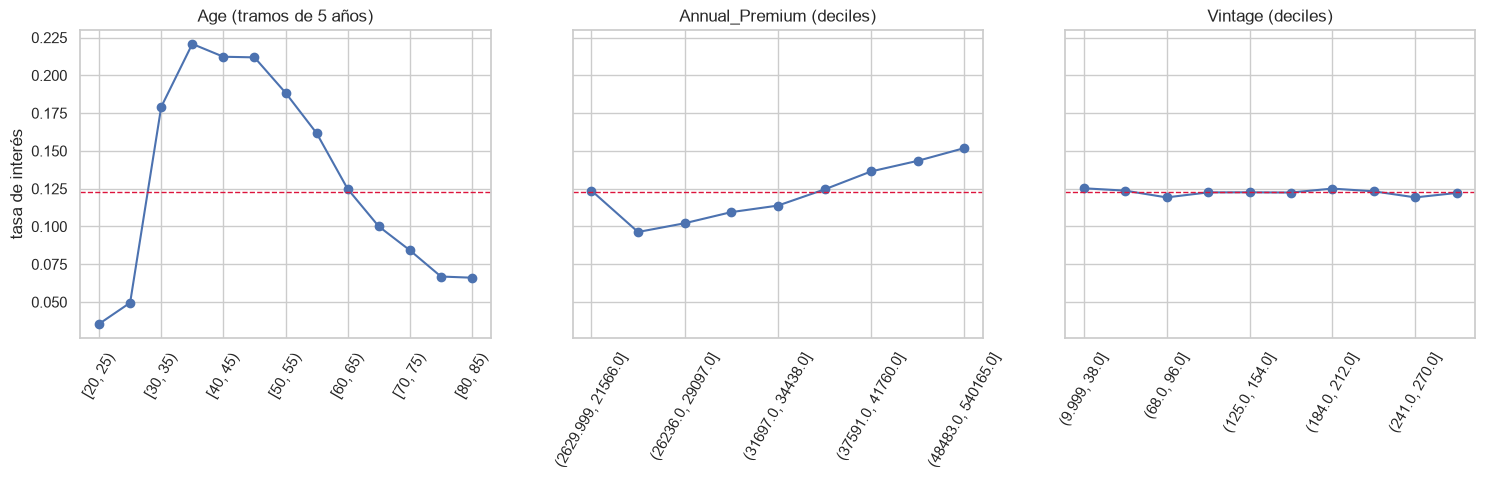

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
age_bins = pd.cut(explore["Age"], bins=range(20, 90, 5), right=False)
explore.groupby(age_bins, observed=True)[TARGET].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Age (tramos de 5 años)")
for ax, c in zip(axes[1:], ["Annual_Premium", "Vintage"]):
    explore.groupby(pd.qcut(explore[c], 10, duplicates="drop"), observed=True)[TARGET].mean().plot(ax=ax, marker="o")
    ax.set_title(f"{c} (deciles)")
for ax in axes:
    ax.axhline(base_rate, color="crimson", ls="--", lw=1); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("tasa de interés")
plt.show()

In [19]:
print("Tasa de interés por tramo de edad:")
display(rate_table(explore.assign(tramo_edad=age_bins), "tramo_edad"))

Tasa de interés por tramo de edad:


,filas,interesados,tasa,% filas,lift
tramo_edad,,,,,
"[20, 25)",75149,2670,0.0355,24.65,0.29
"[25, 30)",49017,2428,0.0495,16.08,0.40
"[30, 35)",21336,3821,0.1791,7.00,1.46
"[35, 40)",22084,4876,0.2208,7.24,1.80
"[40, 45)",31690,6728,0.2123,10.39,1.73
"[45, 50)",29737,6301,0.2119,9.75,1.73
"[50, 55)",22444,4230,0.1885,7.36,1.54
"[55, 60)",15934,2577,0.1617,5.23,1.32
"[60, 65)",12766,1593,0.1248,4.19,1.02


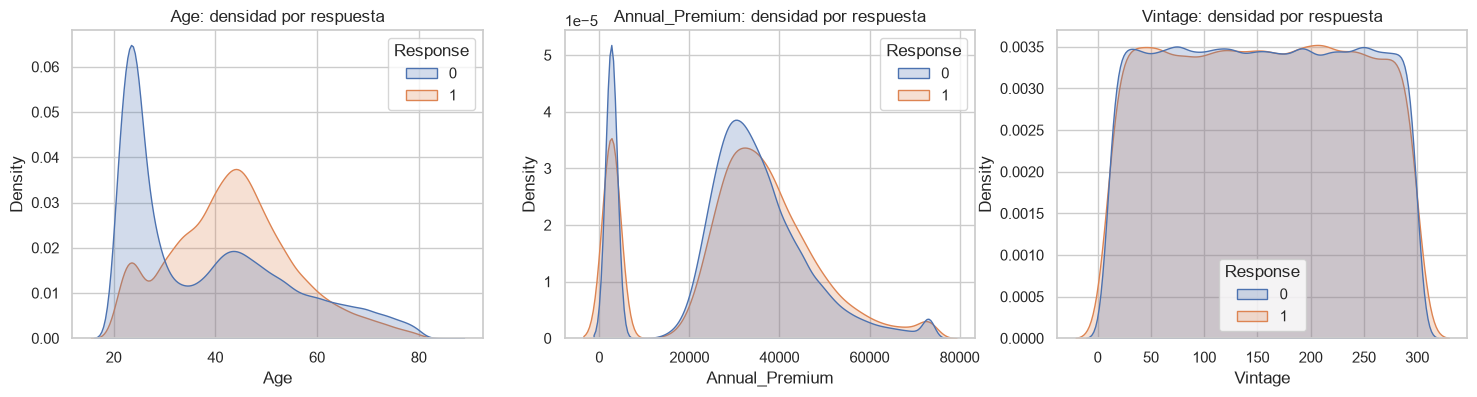

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, num):
    data = explore[c].clip(upper=explore[c].quantile(.99)) if c == "Annual_Premium" else explore[c]
    sns.kdeplot(x=data, hue=explore[TARGET], common_norm=False, ax=ax, fill=True)
    ax.set_title(f"{c}: densidad por respuesta")
plt.show()

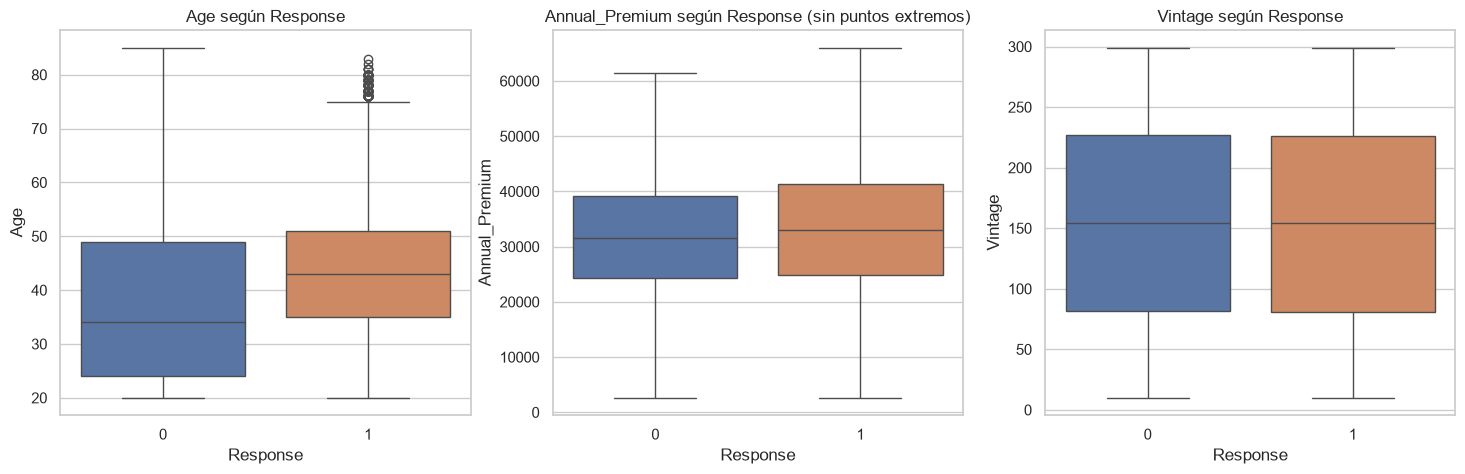

In [21]:
# Diagramas de caja: mediana, cuartiles y extremos de cada numérica según Response (0 = no, 1 = sí)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, num):
    sns.boxplot(data=explore, x=TARGET, y=c, ax=ax, hue=TARGET, palette=["#4C72B0", "#DD8452"], legend=False,
                showfliers=(c != "Annual_Premium"))
    ax.set_title(f"{c} según Response" + (" (sin puntos extremos)" if c == "Annual_Premium" else ""))
plt.show()

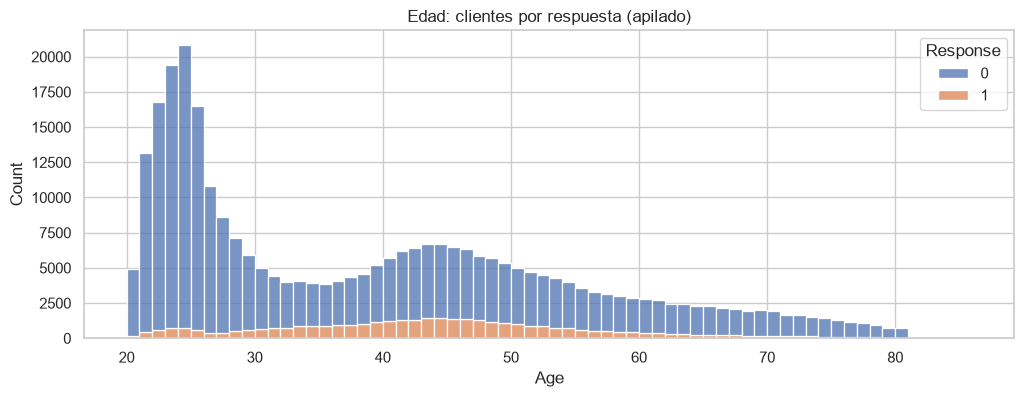

Response                     0         1
Age            count  267519.0   37368.0
               mean       38.2      43.4
               std        15.8      12.2
               min        20.0      20.0
               25%        24.0      35.0
               50%        34.0      43.0
               75%        49.0      51.0
               max        85.0      83.0
Annual_Premium count  267519.0   37368.0
               mean    30447.7   31619.3
               std     17059.7   18441.5
               min      2630.0    2630.0
               25%     24346.0   24879.0
               50%     31526.0   33056.5
               75%     39171.0   41334.2
               max    540165.0  489663.0
Vintage        count  267519.0   37368.0
               mean      154.4     154.0
               std        83.7      83.8
               min        10.0      10.0
               25%        82.0      81.0
               50%       154.0     154.0
               75%       227.0     226.0
               max       299.0     299.0

In [22]:
# Histograma de edad: cuántos clientes hay en cada edad y cuántos de ellos se interesan
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=explore, x="Age", hue=TARGET, bins=range(20, 87), multiple="stack", ax=ax)
ax.set_title("Edad: clientes por respuesta (apilado)")
plt.show()
explore.groupby(TARGET)[num].describe().T.round(1)

### 6.4 Ranking común: información mutua

In [23]:
from sklearn.feature_selection import mutual_info_classif

encoded = pd.DataFrame({
    "Age": explore["Age"],
    "Annual_Premium": explore["Annual_Premium"],
    "Vintage": explore["Vintage"],
    "Gender": explore["Gender"].eq("Male").astype(int),
    "Driving_License": explore["Driving_License"],
    "Previously_Insured": explore["Previously_Insured"],
    "Vehicle_Damage": explore["Vehicle_Damage"].eq("Yes").astype(int),
    "Vehicle_Age": explore["Vehicle_Age"].map({"< 1 Year": 0, "1-2 Year": 1, "> 2 Years": 2}),
    "Region_Code": explore["Region_Code"].astype(int),
    "Policy_Sales_Channel": explore["Policy_Sales_Channel"].astype(int),
})
discrete = [c not in num for c in encoded.columns]
sample = encoded.sample(100_000, random_state=42)
mi = mutual_info_classif(sample, explore.loc[sample.index, TARGET], discrete_features=discrete, random_state=42)
ranking = pd.Series(mi, index=encoded.columns, name="informacion_mutua").sort_values(ascending=False)
ranking.round(4).to_frame()

,informacion_mutua
Previously_Insured,0.0791
Vehicle_Damage,0.0782
Policy_Sales_Channel,0.0388
Age,0.0302
Vehicle_Age,0.0252
Region_Code,0.0088
Annual_Premium,0.0047
Gender,0.0013
Driving_License,0.0001
Vintage,0.0000


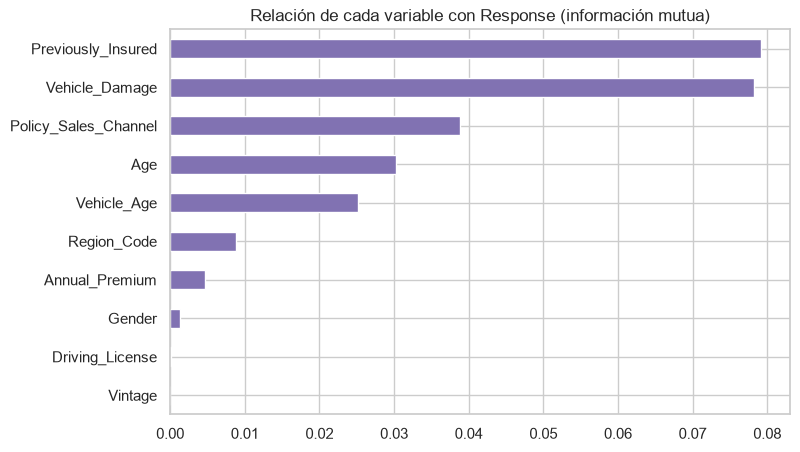

,informacion_mutua,v_cramer,abs_r_punto_biserial,auc_univariada
Previously_Insured,0.0791,0.3413,NaN,NaN
Vehicle_Damage,0.0782,0.3542,NaN,NaN
Policy_Sales_Channel,0.0388,0.2633,NaN,NaN
Age,0.0302,NaN,0.1112,0.6269
Vehicle_Age,0.0252,0.2213,NaN,NaN
Region_Code,0.0088,0.1374,NaN,NaN
Annual_Premium,0.0047,NaN,0.0223,0.5301
Gender,0.0013,0.0513,NaN,NaN
Driving_License,0.0001,0.0100,NaN,NaN
Vintage,0.0000,NaN,0.0016,0.4986


In [24]:
summary = ranking.to_frame()
summary["v_cramer"] = assoc_cat["v_cramer"]
summary["abs_r_punto_biserial"] = assoc_num["r_punto_biserial"].abs()
summary["auc_univariada"] = assoc_num["auc_univariada"]
ax = summary["informacion_mutua"].sort_values().plot.barh(figsize=(8, 5), color="#8172B2")
ax.set_title("Relación de cada variable con Response (información mutua)")
plt.show()
summary.round(4)

### 6.5 ¿Las variables dicen lo mismo? (redundancia e interacción)

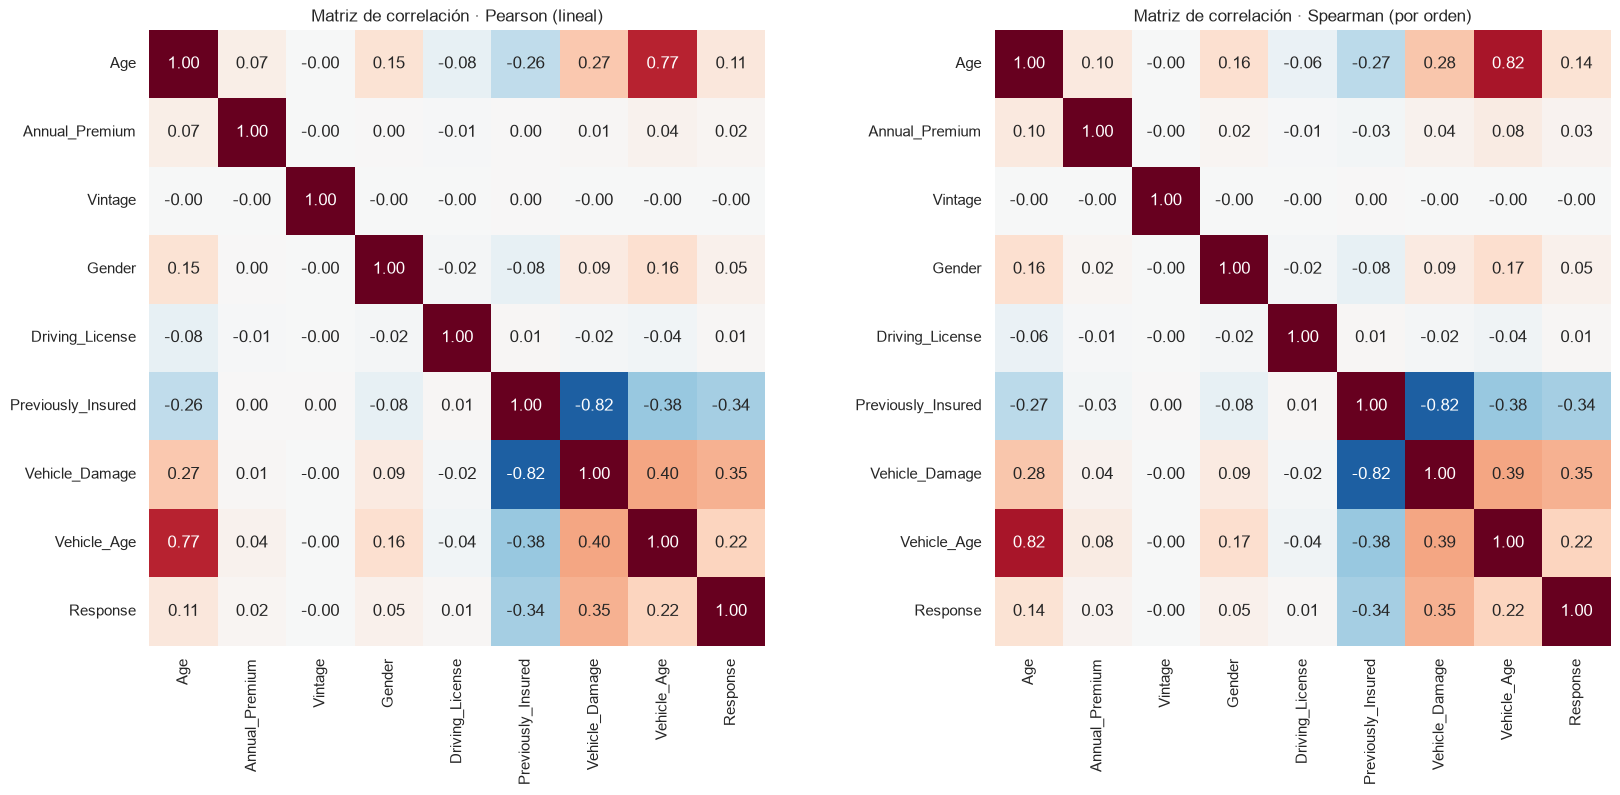

In [25]:
# Region_Code y Policy_Sales_Channel son códigos: su correlación numérica no tiene sentido, se excluyen de la matriz.
corr_vars = encoded.drop(columns=["Region_Code", "Policy_Sales_Channel"]).assign(Response=explore[TARGET])
corr_pearson = corr_vars.corr(method="pearson")
corr_spearman = corr_vars.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (name, m) in zip(axes, [("Pearson (lineal)", corr_pearson), ("Spearman (por orden)", corr_spearman)]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True, cbar=False)
    ax.set_title(f"Matriz de correlación · {name}")
plt.show()

In [26]:
# Correlación de cada variable con Response, ordenada por fuerza
pd.DataFrame({"pearson": corr_pearson["Response"], "spearman": corr_spearman["Response"]}).drop("Response") \
    .sort_values("pearson", key=abs, ascending=False).round(4)

,pearson,spearman
Vehicle_Damage,0.3542,0.3542
Previously_Insured,-0.3413,-0.3413
Vehicle_Age,0.2213,0.2201
Age,0.1112,0.1443
Gender,0.0513,0.0513
Annual_Premium,0.0223,0.0343
Driving_License,0.0100,0.0100
Vintage,-0.0016,-0.0016


In [27]:
# Pares de variables muy correlacionados entre sí (|r| >= 0,5): dicen casi lo mismo
pairs = corr_spearman.drop(index="Response", columns="Response").where(lambda m: np.triu(np.ones(m.shape, bool), 1)).stack()
pairs[pairs.abs() >= 0.5].sort_values(key=abs, ascending=False).round(3).to_frame("spearman")

,,spearman
Previously_Insured,Vehicle_Damage,-0.825
Age,Vehicle_Age,0.824


In [28]:
inter = explore.pivot_table(index=["Previously_Insured", "Vehicle_Damage"], columns="Vehicle_Age",
                            values=TARGET, aggfunc=["mean", "size"])[[("mean", a) for a in order_age] + [("size", a) for a in order_age]]
inter.round(4)

mean                        size  \
Vehicle_Age                       < 1 Year 1-2 Year > 2 Years < 1 Year   
Previously_Insured Vehicle_Damage                                        
0                  No               0.0316   0.0448    0.0000     9068   
                   Yes              0.1542   0.2789    0.2937    35393   
1                  No               0.0003   0.0006    0.0000    84260   
                   Yes              0.0064   0.0087    0.0357     3131   

                                                      
Vehicle_Age                       1-2 Year > 2 Years  
Previously_Insured Vehicle_Damage                     
0                  No                10071         7  
                   Yes               97871     12800  
1                  No                47517         5  
                   Yes                4736        28

**Lectura: qué se relaciona con la respuesta** (porción de exploración, 304.887 clientes, tasa global 12,26 %)

| Fuerza | Variable | Evidencia |
|---|---|---|
| **Fuerte** | `Vehicle_Damage` | Con daño previo 23,8 % se interesa; sin daño, 0,5 %. V de Cramér 0,354, información mutua 0,080 |
| **Fuerte** | `Previously_Insured` | Sin seguro de vehículo 22,6 %; ya asegurado **0,08 %** (118 de 139.677). V 0,341, IM 0,079 |
| **Media** | `Policy_Sales_Channel` | Entre canales grandes la tasa va de 2,2 % (canal 160) a 32,7 %; los canales 152 y 160 (41 % de la base) casi no convierten. V 0,263 |
| **Media** | `Vehicle_Age` | < 1 año 4,4 %; 1–2 años 17,4 %; > 2 años 29,3 %. V 0,221 |
| **Media** | `Age` | Relación **no lineal en forma de campana**: 3,6 % de 20 a 25 años, máximo 22 % entre 35 y 50, baja a 6,6 % desde los 75. r = 0,111, Spearman 0,144, AUC 0,627; mediana 34 (no) vs 43 (sí) |
| Débil | `Region_Code` | Entre regiones grandes la tasa va de 4,6 % a 18,8 %; la región 28 (28 % de clientes) tiene 18,7 %. V 0,137 |
| Muy débil | `Gender` | Hombres 13,8 %, mujeres 10,4 %. V 0,051 |
| Muy débil | `Annual_Premium` | r = 0,022, AUC 0,530; mediana 31.526 vs 33.057 |
| **Ninguna** | `Vintage` | r = −0,002 (p = 0,38), AUC 0,499; distribuciones idénticas en los dos grupos |
| **Ninguna** | `Driving_License` | V 0,010, IM 0,0001; casi constante |

**Redundancia (matriz de correlación):** `Previously_Insured` y `Vehicle_Damage` dicen casi lo mismo (Spearman −0,825), igual que `Age` y
`Vehicle_Age` (0,824). **Interacción clave:** quien ya tiene seguro casi nunca se interesa (≤ 3,6 % en todas las combinaciones); quien no lo
tiene y tuvo daño llega a 15,4 %–29,4 % según la antigüedad del vehículo.

**Implicaciones para el modelo:** la señal está concentrada en 2–3 variables y varias relaciones **no son lineales** (edad, canal, región):
conviene probar modelos de árboles además de la regresión logística. Que una variable tenga poca relación aquí **no** la saca del modelo:
eso se decide en la etapa 04 con validación.

## 7. Tabla de decisiones

Se copia tal cual a `reports/01_eda.md`. Cada decisión se implementa en `src/proyecto/data/` con su prueba en la etapa 03.

| # | Hallazgo (con cifra) | Decisión | Motivo | Función que la implementa |
|---|---|---|---|---|
| 1 | `id` único en las 381.109 filas; `Response` 12,26 % positivos | Partir **por fila, estratificado por `Response`**: 80 % entrenamiento/validación y 20 % prueba, `random_state=42`; validación cruzada con `StratifiedKFold` | No hay clientes repetidos; la estratificación mantiene la proporción de interesados en cada parte | `split_train_test` |
| 2 | `id` es un consecutivo sin significado | Quitar `id` de las variables al cargar | No describe al cliente; el modelo podría memorizarlo | `drop_id_column` |
| 3 | 269 filas repetidas sin contar `id` (0,07 %); 53 grupos con respuesta contradictoria | Quitar repetidas **solo en entrenamiento**, conservando la primera | Evita contar dos veces al mismo perfil; el efecto es pequeño y no se toca la prueba | `drop_duplicate_rows` |
| 4 | `Annual_Premium` = 2.630 en 17,02 % de las filas (siguiente valor 6.098) | Crear `is_min_premium` (1 si vale 2.630) y conservar el valor | Es un piso o valor por defecto, no un monto comparable; el indicador deja que el modelo lo trate aparte | `add_min_premium_flag` |
| 5 | `Annual_Premium` con cola larga: máx. 540.165, 2,71 % sobre el límite IQR (61.892) | Aplicar `log1p` dentro del `Pipeline` | Reduce el peso de los extremos en modelos lineales sin borrar filas | `log_transform_premium` |
| 6 | `Region_Code` y `Policy_Sales_Channel` son códigos guardados como decimal; 134 canales con < 1.000 filas (4,12 %) | Convertir a categoría entera y agrupar categorías con < 1.000 filas **en entrenamiento** como `"otros"` (dentro del `Pipeline`) | Son etiquetas, no cantidades; las categorías raras darían tasas inestables | `cast_codes_to_category`, `group_rare_categories` |
| 7 | `Vehicle_Age` ordenada (4,4 % → 17,4 % → 29,3 %); `Vehicle_Damage` y `Gender` binarias en texto | Codificar `Vehicle_Age` como 0/1/2 y las binarias como 0/1 | Conserva el orden real y deja las columnas listas para cualquier modelo | `encode_categoricals` |
| 8 | `Policy_Sales_Channel` es el canal de contacto (posible fuga); V de Cramér 0,263 | Mantenerla, pero medir el modelo **con y sin** ella en la etapa 04 | Si el canal se decide en la campaña, el modelo no podría usarlo antes de llamar | — (experimento en etapa 04) |
| 9 | `Vintage` (r = −0,002, AUC 0,499) y `Driving_License` (0,21 % en 0, V 0,010) sin relación con `Response` | Conservarlas en el preprocesamiento y marcarlas como candidatas a salir en la etapa 04 | Se quitan solo si la validación confirma que no aportan | — (etapa 04) |
| 10 | Hombres 13,8 % vs mujeres 10,4 % de interés; tasas por edad de 3,6 % a 22 % | Evaluar el modelo con y sin `Gender`, y reportar recall por género y tramo de edad | Atributos sensibles: el modelo no debe dejar de contactar a un grupo sin razón de negocio | — (etapas 04 y 07) |

## Entregable de esta etapa

- [x] Este notebook ejecuta de principio a fin.
- [x] La tabla de decisiones tiene **al menos 5** filas con cifra y motivo.
- [x] `reports/01_eda.md` está actualizado.
- [x] Declaré mi **unidad de análisis** por escrito.

**Siguiente:** `03_preprocesamiento.ipynb`.